# 04 - News Sentiment

Check the news table for recent sentiment.


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
DB = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "database" / "market.db"

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from database.config.api.binance import get_klines

def fetch(symbol, interval, limit=500):
    raw = get_klines(symbol, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

def action_block(name, action, reason, price=None, entry=None, stop=None,
                 target=None, conf=None, extra=None):
    print("=" * 62)
    print(f"  {name}")
    print("=" * 62)
    print(f"  time   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
    if price is not None: print(f"  price  : {price:,.2f}")
    if conf  is not None: print(f"  conf   : {conf:.2f}")
    print(f"  ACTION : {action}")
    print(f"  REASON : {reason}")
    if entry is not None:
        print(f"  entry  : {entry:,.2f}   stop: {stop:,.2f}   target: {target:,.2f}")
    if extra:
        for k, v in extra.items():
            print(f"  {k:<6} : {v}")
    print("=" * 62)
    return {"action": action, "reason": reason, "price": price,
            "entry": entry, "stop": stop, "target": target, "conf": conf}

## 1. Load news from DB

In [2]:
try:
    news = sql("SELECT ts, source, title, sentiment FROM news ORDER BY ts DESC LIMIT 100")
    news["date"] = pd.to_datetime(news.ts, unit="ms")
    print("rows:", len(news))
    news.head(10)
except Exception as e:
    print("news table empty or missing:", e)
    news = pd.DataFrame()

rows: 2


## 2. Sentiment distribution

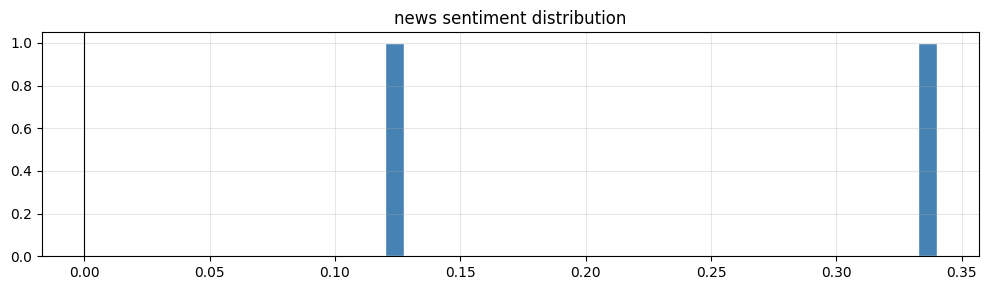

In [3]:
if not news.empty and "sentiment" in news.columns:
    fig, ax = plt.subplots(figsize=(10, 3))
    news["sentiment"].dropna().hist(bins=30, ax=ax, color="steelblue", edgecolor="white")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("news sentiment distribution")
    plt.tight_layout(); plt.show()

## 3. Recent news score

In [4]:
if not news.empty and "sentiment" in news.columns:
    recent = news.head(20)
    avg = float(recent["sentiment"].mean())
    print(f"avg sentiment (last 20): {avg:+.3f}")
else:
    avg = 0.0
    print("no sentiment data — treating as neutral")

avg sentiment (last 20): +0.230


## 4. Action

In [5]:
if avg > 0.2:   action, reason = "LONG", "positive news sentiment"
elif avg < -0.2: action, reason = "SHORT", "negative news sentiment"
else:            action, reason = "FLAT", "neutral news — no edge"
action_block("NEWS SENTIMENT", action, reason, conf=abs(avg))

  NEWS SENTIMENT
  time   : 2026-10-04 10:41 UTC
  conf   : 0.23
  ACTION : LONG
  REASON : positive news sentiment


{'action': 'LONG',
 'reason': 'positive news sentiment',
 'price': None,
 'entry': None,
 'stop': None,
 'target': None,
 'conf': 0.23}